# PCA Visualizations of mGLI Embeddings

In [17]:
import torch
import glob
import os
from collections import defaultdict
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
from src.utils import load_embedding

Loading and standardizing mGLI embeddings

In [18]:
EXPECTED_DIM = 81
ROOT = "data/mGLI_embeddings"

embs = []
labels = []

pt_paths = sorted(glob.glob(os.path.join(ROOT, "*", "*.pt")))

for p in pt_paths:
    if not os.path.exists(p):
        skipped_missing += 1
        continue

    x = load_embedding(p)  # must return 1D torch.Tensor

    if x.numel() != EXPECTED_DIM:
        skipped_bad += 1
        continue

    protein_id = os.path.basename(os.path.dirname(p))  # folder name
    embs.append(x)
    labels.append(protein_id)

X = torch.stack(embs, dim=0)  # (N, D)

# Standardize across samples for visualization
X_np = X.numpy()
mu = X_np.mean(axis=0, keepdims=True)
sd = X_np.std(axis=0, keepdims=True) + 1e-6
X_np = (X_np - mu) / sd

print(len(labels), "samples loaded.")

500 samples loaded.


PCA plots

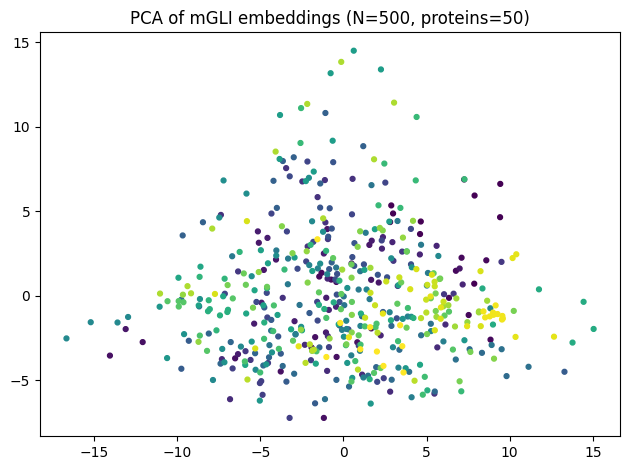

In [19]:
# PCA plot on raw mGLI embeddings

Z = PCA(n_components=2).fit_transform(X_np)
uniq = {p: i for i, p in enumerate(sorted(set(labels)))}
c = [uniq[p] for p in labels]

plt.figure()
plt.scatter(Z[:, 0], Z[:, 1], c=c, s=12)
plt.title(f"PCA of mGLI embeddings (N={X_np.shape[0]}, proteins={len(set(labels))})")
plt.tight_layout()

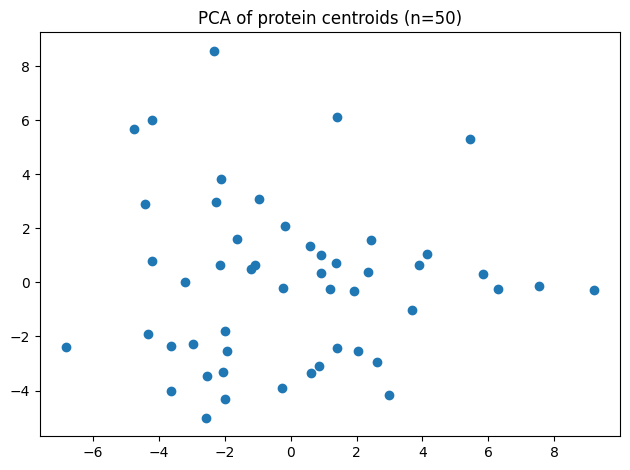

In [20]:
# PCA on protein centroids

groups = defaultdict(list)
for x, pid in zip(X_np, labels):
    groups[pid].append(x)

C = np.stack([np.mean(v, axis=0) for v in groups.values()])
Z = PCA(n_components=2).fit_transform(C)

plt.figure()
plt.scatter(Z[:, 0], Z[:, 1])
plt.title(f"PCA of protein centroids (n={len(groups)})")
plt.tight_layout()